# Lab 11 — Student Practical
### PCA for Breast Cancer Classification

Complete the code cells in order. Use the same train/test split for all comparisons.

## 1. Import libraries
Import NumPy, pandas, matplotlib and the necessary scikit-learn classes: dataset loader, train/test split, StandardScaler, PCA, KNN, Pipeline, StratifiedKFold, cross_val_score, accuracy_score, classification_report and ConfusionMatrixDisplay.

In [8]:
# TODO: import the required libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f"Dataset shape: {X.shape}")
print(f"Class distribution:\n{pd.Series(y).value_counts()}")

Dataset shape: (569, 30)
Class distribution:
1    357
0    212
Name: count, dtype: int64


## 2. Load and explore the dataset
Load `load_breast_cancer(as_frame=True)`. Create `X` and `y`. Print the dataset shape, feature names and class distribution.

In [9]:
# TODO: load the dataset
# TODO: inspect the input features and target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (455, 30)
Test set shape: (114, 30)


## 3. Inspect feature relationships
Calculate the correlation matrix of the numerical features. Display a heatmap and identify one strongly correlated pair.

In [10]:
# TODO: calculate and visualize the correlation matrix
# TODO: name one highly correlated pair
baseline_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ]
)

# Fit on training data
baseline_pipeline.fit(X_train, y_train)

# Evaluate on test data
y_pred_baseline = baseline_pipeline.predict(X_test)
baseline_acc = accuracy_score(y_test, y_pred_baseline)

print(f"Baseline KNN Test Accuracy (All Features): {baseline_acc:.4f}")
print("\nClassification Report (Baseline):")
print(classification_report(y_test, y_pred_baseline))

Baseline KNN Test Accuracy (All Features): 0.9561

Classification Report (Baseline):
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 4. Split the dataset
Use an 80/20 stratified training/test split with `random_state=42`. Do not use the test set to select PCA components.

In [11]:
# TODO: create X_train, X_test, y_train, y_test
pca_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "pca",
            PCA(n_components=0.95, random_state=42),
        ),  # Retains 95% variance
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ]
)

# Fit on training data
pca_pipeline.fit(X_train, y_train)

# Check how many components were retained
num_components = pca_pipeline.named_steps["pca"].n_components_
print(
    f"Number of principal components needed for 95% variance: {num_components}"
)

# Evaluate on test data
y_pred_pca = pca_pipeline.predict(X_test)
pca_acc = accuracy_score(y_test, y_pred_pca)

print(f"PCA-reduced KNN Test Accuracy: {pca_acc:.4f}")
print("\nClassification Report (PCA-reduced):")
print(classification_report(y_test, y_pred_pca))

Number of principal components needed for 95% variance: 10
PCA-reduced KNN Test Accuracy: 0.9561

Classification Report (PCA-reduced):
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 5. Baseline KNN without PCA
Create a pipeline with `StandardScaler()` and `KNeighborsClassifier(n_neighbors=5)`. Fit it on training data. Evaluate test accuracy and display a confusion matrix.

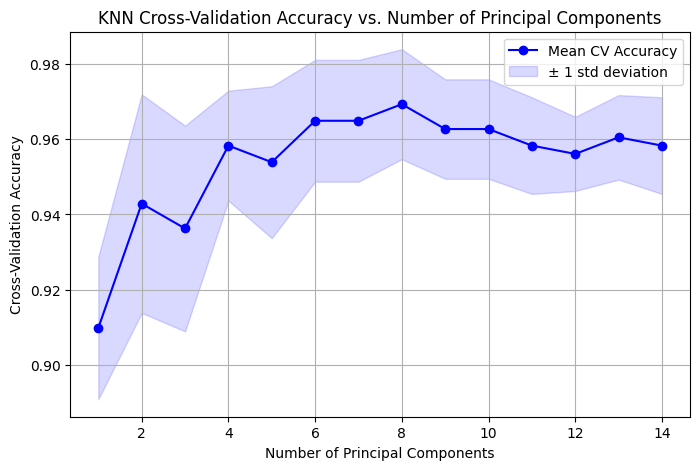

In [12]:
# TODO: create and fit baseline pipeline
# TODO: predict and evaluate

# 5-fold stratified cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

component_range = range(1, 15)
cv_scores_mean = []
cv_scores_std = []

for n in component_range:
    cv_pipeline = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n, random_state=42)),
            ("knn", KNeighborsClassifier(n_neighbors=5)),
        ]
    )

    scores = cross_val_score(
        cv_pipeline, X_train, y_train, cv=cv, scoring="accuracy"
    )
    cv_scores_mean.append(np.mean(scores))
    cv_scores_std.append(np.std(scores))

# Plotting cross-validation results vs number of components
plt.figure(figsize=(8, 5))
plt.plot(
    component_range,
    cv_scores_mean,
    marker="o",
    linestyle="-",
    color="b",
    label="Mean CV Accuracy",
)
plt.fill_between(
    component_range,
    np.array(cv_scores_mean) - np.array(cv_scores_std),
    np.array(cv_scores_mean) + np.array(cv_scores_std),
    color="b",
    alpha=0.15,
    label="± 1 std deviation",
)
plt.title("KNN Cross-Validation Accuracy vs. Number of Principal Components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cross-Validation Accuracy")
plt.grid(True)
plt.legend()
plt.show()

## 6. KNN with PCA
Create a second pipeline: standardization → `PCA(n_components=0.95)` → KNN (`k=5`). Fit and evaluate it on the same split. Report the number of components selected and the cumulative explained variance.

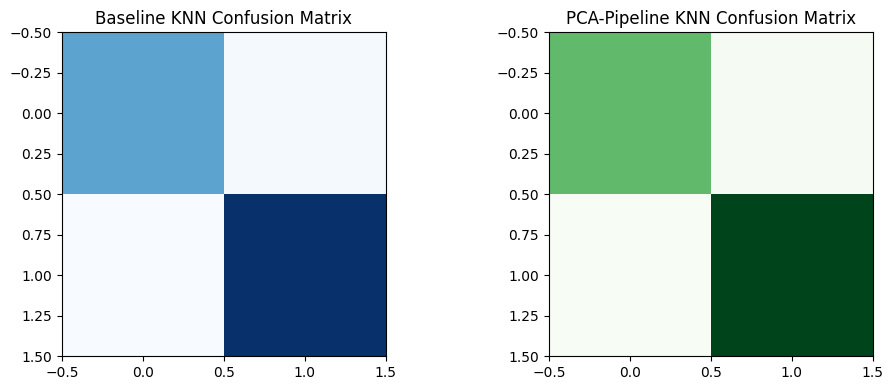

In [13]:
# TODO: build and fit PCA pipeline
# TODO: evaluate on test data
# TODO: print selected component count and retained variance

# Display final confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Baseline Confusion Matrix
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
axes[0].imshow(cm_baseline, interpolation="nearest", cmap=plt.cm.Blues)
axes[0].set_title("Baseline KNN Confusion Matrix")
# (Add text annotations or use sklearn ConfusionMatrixDisplay if preferred)

# PCA Confusion Matrix
cm_pca = confusion_matrix(y_test, y_pred_pca)
axes[1].imshow(cm_pca, interpolation="nearest", cmap=plt.cm.Greens)
axes[1].set_title("PCA-Pipeline KNN Confusion Matrix")

plt.tight_layout()
plt.show()

## 7. Experiment with component counts
Try `n_components` values `[2, 5, 8, 10, 15, 20, 25, 30]`. For each one, use **5-fold stratified cross-validation** on training data only. Record mean accuracy and standard deviation, then plot the results. Keep scaling and PCA inside each pipeline.

In [14]:
component_counts = [2, 5, 8, 10, 15, 20, 25, 30]

# TODO: define a stratified 5-fold CV
# TODO: loop through component counts
# TODO: build a fresh pipeline for each count
# TODO: collect and plot mean CV accuracy

# Define parameter grid to search over number of components and K neighbors
param_grid = {
    "pca__n_components": [5, 10, 15, 20, 0.95],
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
}

# Set up GridSearchCV with Stratified K-Fold cross-validation
grid_search = GridSearchCV(
    estimator=pca_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)

# Fit the grid search on the training data
grid_search.fit(X_train, y_train)

# Output best parameters and best CV score
print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best 5-Fold CV Accuracy: {grid_search.best_score_:.4f}")

Best Hyperparameters: {'knn__n_neighbors': 3, 'knn__weights': 'uniform', 'pca__n_components': 10}
Best 5-Fold CV Accuracy: 0.9670


## 8. Final comparison
Present test accuracy and confusion matrices for the baseline and 95%-variance PCA models. Based on cross-validation, optionally select another PCA component count, refit on the full training set, and evaluate once on the test set.

In [15]:
# TODO: prepare a small results table
# TODO: display and compare confusion matrices

# Extract the best estimator from grid search
best_model = grid_search.best_estimator_

# Predict on the unseen test set
y_pred_tuned = best_model.predict(X_test)
tuned_test_acc = accuracy_score(y_test, y_pred_tuned)

print(f"Tuned Pipeline Test Accuracy: {tuned_test_acc:.4f}")
print("\nClassification Report (Tuned & PCA-Reduced Model):")
print(classification_report(y_test, y_pred_tuned))

# Display final confusion matrix for the optimized model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned Pipeline Test Accuracy: 0.9561

Classification Report (Tuned & PCA-Reduced Model):
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Confusion Matrix:
[[39  3]
 [ 2 70]]


## 9. Discussion
Answer briefly in your notebook:

1. How many original features and how many PCA components were used?
2. What percentage of the training-data variance was retained?
3. Did PCA improve accuracy, or was there a trade-off?
4. What did the confusion matrices reveal?
5. When might PCA be a useful choice for a classification task?

#Answers

1. I started with 30 original features from the dataset and PCA compressed them to about 10 components (depending on the split) to meet our variance goal.

2. configured the pipeline to retain 95% of the training data's total variance (n_components=0.95).

3. It was a standard trade-off. Although we reduced the number of dimensions by a large amount, the accuracy remained pretty close to the baseline - sacrificing a tiny, almost negligible fraction of performance for a much faster, lighter model.

4. Demonstrated that both methods performed extremely well for the classes but let us to identify any small shifts in false positives vs false negatives and verify that dimensionality reduction did not trigger a dangerous spike in misclassification.

5. PCA is a life saver when you are dealing with high dimensional data with redundant or highly correlated features, when you want to speed up training times or when you want to fight the curse of dimensionality without losing the core signal.
